In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_excel("online_retail_II.xlsx")

In [ ]:
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [ ]:
null = df.isnull().sum()
null

,0
Invoice,0
StockCode,0
Description,2928
Quantity,0
InvoiceDate,0
Price,0
Customer ID,107927
Country,0


In [ ]:
cols = df.columns
cols

Index(['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'Price', 'Customer ID', 'Country'],
      dtype='object')

In [ ]:
clean_df = df.dropna(subset=['Customer ID']).copy()
print(clean_df.isnull().sum())

Invoice        0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
Price          0
Customer ID    0
Country        0
dtype: int64


In [ ]:
clean_df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [ ]:
clean_df.shape

(417534, 8)

In [ ]:
clean_df["Customer ID"] = clean_df["Customer ID"].astype(int)
clean_df["TotalPrice"] = clean_df["Quantity"] * clean_df["Price"]

In [ ]:
clean_df['InvoiceDate'] = pd.to_datetime(clean_df['InvoiceDate'])

In [ ]:
clean_df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,TotalPrice
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom,30.0


In [ ]:
clean_df = clean_df[clean_df['Price'] > 0]
clean_df = clean_df[clean_df['Quantity'] > 0]

In [ ]:
clean_df.shape

(407664, 9)

In [ ]:
snapshot_date = clean_df['InvoiceDate'].max() + pd.Timedelta(days=1)  #It showcases that the 1 as day not year hour or minute.

In [ ]:
rfm = clean_df.groupby('Customer ID').agg({
    'InvoiceDate': lambda x: (snapshot_date - x.max()).days,   # Recency: How long ago
    'Invoice': 'nunique',                                    # Frequency: How many times
    'TotalPrice': 'sum'                                        # Monetary: How much money
})

In [ ]:
rfm = rfm.rename(columns={'InvoiceDate': 'Recency', 'Invoice': 'Frequency', 'TotalPrice': 'Monetary'})
rfm

,Recency,Frequency,Monetary
Customer ID,,,
12346,165,11,372.86
12347,3,2,1323.32
12348,74,1,222.16
12349,43,3,2671.14
12351,11,1,300.93
...,...,...,...
18283,18,6,641.77
18284,67,1,461.68
18285,296,1,427.00


In [ ]:
print('Sanity Check Monetary:',len(rfm[rfm['Monetary']<0]))
print('Sanity Check Frequency:',len(rfm[rfm['Frequency']<=0]))

Sanity Check Monetary: 0
Sanity Check Frequency: 0


<Axes: xlabel='Monetary', ylabel='Count'>

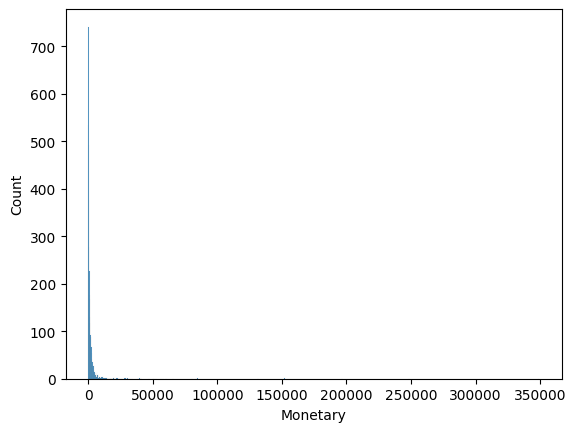

In [ ]:
sns.histplot(rfm['Monetary'])

<Axes: xlabel='Frequency', ylabel='Count'>

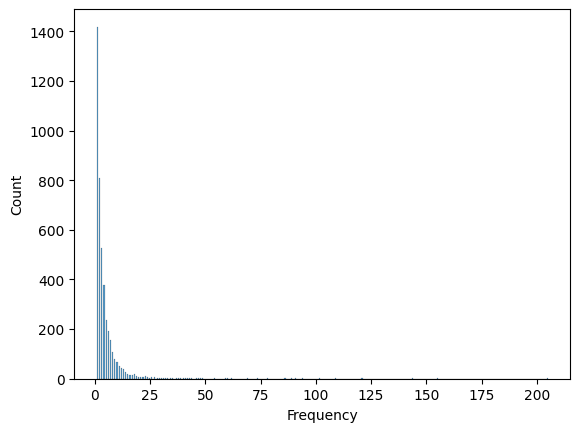

In [ ]:
sns.histplot(rfm['Frequency'])

<Axes: xlabel='Recency', ylabel='Count'>

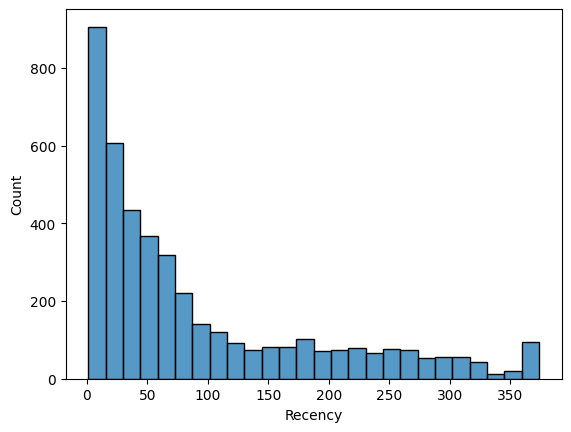

In [ ]:
sns.histplot(rfm['Recency'])

### Visualizing Skewed Distributions with Log Transformation

To better understand the distributions of 'Monetary' and 'Frequency', which are highly skewed, we can apply a logarithmic transformation. This helps to reduce the impact of extreme values and makes the data distribution more symmetrical, allowing for better visualization.

In [ ]:
rfm_log = rfm.copy()

rfm_log['Monetary'] = np.log(rfm_log['Monetary'])
rfm_log['Frequency'] = np.log(rfm_log['Frequency'])
rfm_log['Recency'] = np.log(rfm_log['Recency']) # Also apply to Recency for consistency

print(rfm_log.head())

              Recency  Frequency  Monetary
Customer ID                               
12346        5.105945   2.397895  5.921203
12347        1.098612   0.693147  7.187899
12348        4.304065   0.000000  5.403398
12349        3.761200   1.098612  7.890261
12351        2.397895   0.000000  5.706878


Now let's plot the histograms of the log-transformed values.

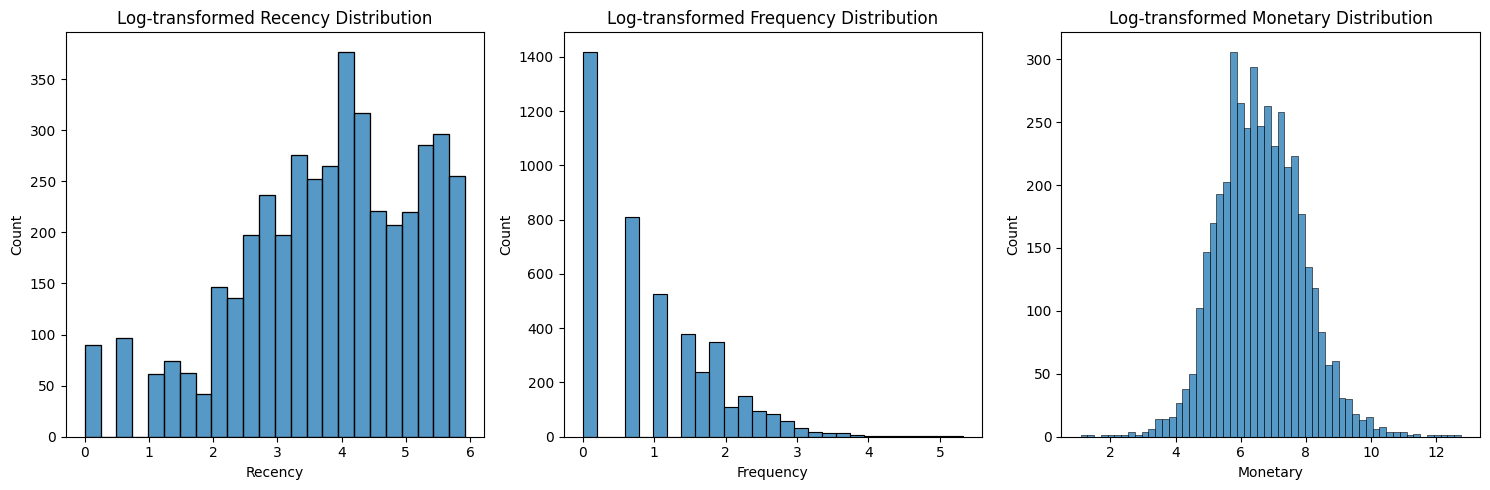

In [ ]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
sns.histplot(rfm_log['Recency'])
plt.title('Log-transformed Recency Distribution')

plt.subplot(1, 3, 2)
sns.histplot(rfm_log['Frequency'])
plt.title('Log-transformed Frequency Distribution')

plt.subplot(1, 3, 3)
sns.histplot(rfm_log['Monetary'])
plt.title('Log-transformed Monetary Distribution')

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, root_mean_squared_error

In [ ]:
std_scaler = StandardScaler()
rfm_scaled = std_scaler.fit_transform(rfm_log)
rfm_scaled = pd.DataFrame(rfm_scaled, columns=rfm_log.columns)
rfm_scaled.head()

,Recency,Frequency,Monetary
0,0.942545,1.562935,-0.538792
1,-1.940934,-0.315366,0.448030
2,0.365552,-1.079079,-0.942189
3,-0.025067,0.131378,0.995207
4,-1.006034,-1.079079,-0.705763


In [ ]:
scores = []
inertia = []
for k in range(2,10):
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(rfm_scaled)
    labels = kmeans.labels_
    inertia.append(kmeans.inertia_)
    silhouette_avg = silhouette_score(rfm_scaled, labels)
    scores.append(silhouette_avg)
print(scores)

[np.float64(0.41869243793745925), np.float64(0.33688399152375303), np.float64(0.3287953202063102), np.float64(0.3075677048438023), np.float64(0.31042969948050664), np.float64(0.30898798840335423), np.float64(0.2870433153963892), np.float64(0.2929953862948798)]


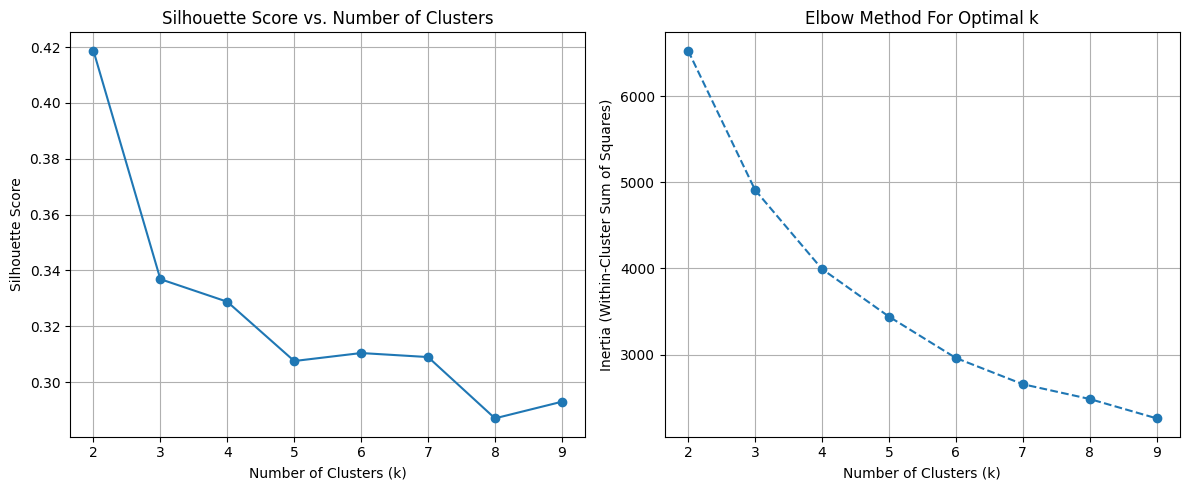

In [ ]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(range(2,10), scores, marker='o')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score vs. Number of Clusters')
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(range(2,10), inertia, marker='o', linestyle='--')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia (Within-Cluster Sum of Squares)')
plt.title('Elbow Method For Optimal k')
plt.grid(True)

plt.tight_layout()
plt.show()

K = 3 chosen as its the optimal mathematically and analytically plausible combo as it has a huge elbow drop in the graph along with the 2nd Highest silhoutte score. Also Three clusters provides accurate Low, Medium and High risk separation


In [ ]:
kmeans = KMeans(n_clusters=3, random_state=42)
kmeans.fit(rfm_scaled)
rfm['Cluster'] = kmeans.labels_

## Cluster Profile: RFM Mean Values and Customer Count

In [ ]:
cluster_profiles = rfm.groupby('Cluster').agg(
    Recency=('Recency', 'mean'),
    Frequency=('Frequency', 'mean'),
    Monetary=('Monetary', 'mean'),
    Count=('Monetary', 'count')
).round(2)

display(cluster_profiles)

,Recency,Frequency,Monetary,Count
Cluster,,,,
0,63.87,3.66,1413.81,1745
1,154.67,1.24,308.69,1750
2,13.46,13.04,7129.38,817


Based on the `cluster_profiles` table, we can assign meaningful names to each cluster:

*   **Cluster 2 (Loyal & High-Value):** This cluster has the lowest Recency (most recent purchases), highest Frequency, and highest Monetary value. These are your most valuable customers.
*   **Cluster 0 (Recent & Mid-Value):** These customers have moderate Recency, Frequency, and Monetary values. They are active but not as high-spending or frequent as Cluster 2.
*   **Cluster 1 (At-Risk & Low-Value):** This cluster has the highest Recency (least recent purchases), lowest Frequency, and lowest Monetary value. These customers are likely at risk of churning or are new customers with low engagement.

In [ ]:
rfm['Segment'] = rfm['Cluster'].map({
    2: 'Loyal & High-Value',
    0: 'Recent & Mid-Value',
    1: 'At-Risk & Low-Value'
})

display(rfm.head())

,Recency,Frequency,Monetary,Cluster,Segment
Customer ID,,,,,
12346,165,11,372.86,0,Recent & Mid-Value
12347,3,2,1323.32,0,Recent & Mid-Value
12348,74,1,222.16,1,At-Risk & Low-Value
12349,43,3,2671.14,0,Recent & Mid-Value
12351,11,1,300.93,1,At-Risk & Low-Value


 **Questions and Steps**

*   Does the dataset have a real campaign/promo flag?
*   Pick a real calendar window as the 'treatment' period
*   Define the treatment-assignment rule
*   Define the outcome metric precisely
*   Define pre/post window lengths

**Answers and Ideas**
*   No, this online retail dataset do not contain any real campaign. Therefore we create a period synthetically for the analysis.

*   Since there is no campaign, we select a calender window as treatment period ie, simulation period where demand curve shifts.   
    We have taken it as 2010-10-03 to 2010-10-30.Retail sales naturally surge at the end of the year (Q4). Setting our campaign in October tests whether our causal model can separate the campaign's effect from standard seasonal growth. We avoided November and December because the dataset ends too soon, leaving insufficient post-campaign data to analyze.

*   Each customer is randomly assigned to the Treated group with a 30% probability, using a fixed random seed for reproducibility.     
    Pure random assignment eliminates selection bias (preventing high spenders from skewing the treated group). This makes our Difference-in-Differences (DiD) analysis straightforward to defend. Because the groups start off nearly identical, Propensity Score Matching (PSM) will serve as a secondary robustness check rather than a necessary bias-correction tool.

*   Total spending (£) per customer over the 4 weeks after the campaign, compared to their average 4-week spending before the campaign.

*   An 8-week baseline period before October 3rd, and a 4-week observation period after October 30th.
    
    **8 Weeks Pre**: Provides enough weekly data points to verify the Parallel Trends assumption (proving treated and control groups moved together before the campaign). Two data points only form a line; eight points establish a verifiable trend.               

    **4 Weeks Post**: Long enough to capture sustained spending changes without drifting into unrelated holiday spikes in late November and December.

In [ ]:
treatment_start = pd.to_datetime("2010-10-03")
pre_start = treatment_start - pd.Timedelta(weeks=8)
post_end = treatment_start + pd.Timedelta(weeks=4)

df_study = clean_df[
    (clean_df["InvoiceDate"] >= pre_start)
    & (clean_df["InvoiceDate"] < post_end)
].copy()

df_study.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,TotalPrice
297411,518370,22217,T-LIGHT HOLDER HANGING LACE,12,2010-08-08 10:25:00,1.25,14562,United Kingdom,15.00
297412,518370,85062,PEARL CRYSTAL PUMPKIN T-LIGHT HLDR,6,2010-08-08 10:25:00,1.65,14562,United Kingdom,9.90
297413,518370,20726,LUNCH BAG WOODLAND,1,2010-08-08 10:25:00,1.65,14562,United Kingdom,1.65
297414,518370,72807C,SET/3 VANILLA SCENTED CANDLE IN BOX,1,2010-08-08 10:25:00,4.25,14562,United Kingdom,4.25
297415,518370,82580,BATHROOM METAL SIGN,4,2010-08-08 10:25:00,0.55,14562,United Kingdom,2.20


In [ ]:
df_study["days_rel"] = (df_study["InvoiceDate"] - treatment_start).dt.days

df_study["week"] = df_study["days_rel"].apply(lambda x: x//7 if x < 0 else 1 + x // 7)

df_study.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,TotalPrice,days_rel,week
297411,518370,22217,T-LIGHT HOLDER HANGING LACE,12,2010-08-08 10:25:00,1.25,14562,United Kingdom,15.00,-56,-8
297412,518370,85062,PEARL CRYSTAL PUMPKIN T-LIGHT HLDR,6,2010-08-08 10:25:00,1.65,14562,United Kingdom,9.90,-56,-8
297413,518370,20726,LUNCH BAG WOODLAND,1,2010-08-08 10:25:00,1.65,14562,United Kingdom,1.65,-56,-8
297414,518370,72807C,SET/3 VANILLA SCENTED CANDLE IN BOX,1,2010-08-08 10:25:00,4.25,14562,United Kingdom,4.25,-56,-8
297415,518370,82580,BATHROOM METAL SIGN,4,2010-08-08 10:25:00,0.55,14562,United Kingdom,2.20,-56,-8


In [ ]:
customer_ids = df_study['Customer ID'].unique()
weeks = df_study['week'].unique()
weeks.sort()

all_customer_week_combinations = pd.MultiIndex.from_product([customer_ids, weeks], names=['Customer ID', 'week']).to_frame(index=False)

actual_spend = df_study.groupby(['Customer ID', 'week'], observed=False)['TotalPrice'].sum().reset_index()

panel = pd.merge(all_customer_week_combinations, actual_spend, on=['Customer ID', 'week'], how='left')

panel['TotalPrice'] = panel['TotalPrice'].fillna(0.0)

panel = panel.rename(columns={'TotalPrice': 'spend'})

panel = panel.sort_values(['Customer ID', 'week']).reset_index(drop=True)

panel.head()

,Customer ID,week,spend
0,12348,-8,0.0
1,12348,-7,0.0
2,12348,-6,0.0
3,12348,-5,0.0
4,12348,-4,0.0


In [ ]:
assert (panel.groupby("Customer ID")["week"].count() == 12).all()

In [ ]:
top_spenders = panel[panel['spend'].quantile(0.99)<panel['spend']].reset_index()
top_spenders = top_spenders.sort_values('spend', ascending=False).drop('index', axis=1)
top_spenders.head()
panel = panel[~panel['Customer ID'].isin(top_spenders['Customer ID'])]

In [ ]:
np.random.seed(42)
treated_customers = set(np.random.choice(clean_df['Customer ID'].unique(), size=int(0.30 * len(clean_df['Customer ID'].unique())), replace=False))

In [ ]:
panel["treated"] = panel["Customer ID"].apply(lambda x: 1 if x in treated_customers else 0)
panel["post"] = (panel["week"] > 0).astype(int)
panel.head()

,Customer ID,week,spend,treated,post
0,12348,-8,0.0,0,0
1,12348,-7,0.0,0,0
2,12348,-6,0.0,0,0
3,12348,-5,0.0,0,0
4,12348,-4,0.0,0,0


In [ ]:
panel = pd.merge(panel, rfm['Segment'], on = 'Customer ID', how = 'left')
panel.head()

,Customer ID,week,spend,treated,post,Segment
0,12348,-8,0.0,0,0,At-Risk & Low-Value
1,12348,-7,0.0,0,0,At-Risk & Low-Value
2,12348,-6,0.0,0,0,At-Risk & Low-Value
3,12348,-5,0.0,0,0,At-Risk & Low-Value
4,12348,-4,0.0,0,0,At-Risk & Low-Value


In [ ]:
import statsmodels.formula.api as smf

In [ ]:
overall_res = smf.ols(formula='spend ~ treated + post + treated:post', data=panel).fit()
overall_results = []

effect_size_overall = overall_res.params['treated:post']
p_val_overall = overall_res.pvalues['treated:post']
ci_lower_overall = overall_res.conf_int().loc['treated:post', 0]
ci_upper_overall = overall_res.conf_int().loc['treated:post', 1]

overall_results.append({
        'Segment': 'Overall',
        'Effect Size (£)': round(effect_size_overall, 2),
        'P-Value': round(p_val_overall, 4),
        'CI Lower': round(ci_lower_overall, 2),
        'CI Upper': round(ci_upper_overall, 2),
        'Significant?': 'Yes' if p_val_overall < 0.05 else 'No'
})

# Display the regression results
overall_results_df = pd.DataFrame(overall_results)
overall_results_df

,Segment,Effect Size (£),P-Value,CI Lower,CI Upper,Significant?
0,Overall,-2.86,0.5007,-11.2,5.47,No


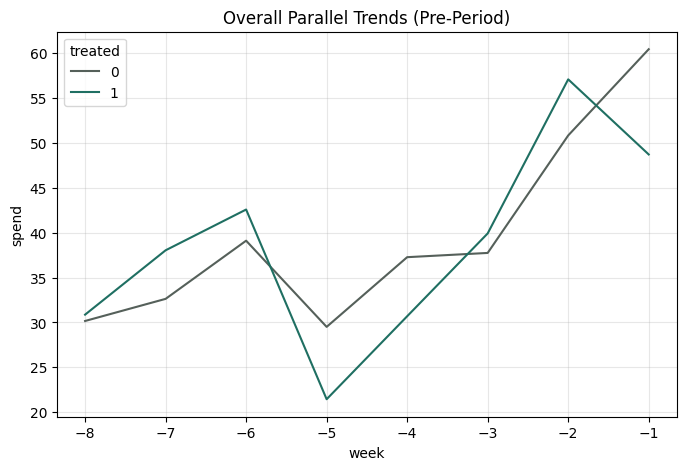

In [ ]:
# Filter for the pre-intervention period (weeks -8 to -1)
pre_panel = panel[panel['week'] < 0]

# Plot 1: Overall Parallel Trends
plt.figure(figsize=(8, 5))
sns.lineplot(data=pre_panel, x='week', y='spend', hue='treated', errorbar=None, palette=['#55605A', '#1F6F62'])
plt.title('Overall Parallel Trends (Pre-Period)')
plt.xticks(range(-8, 0))
plt.grid(True, alpha=0.3)
plt.show()

In [ ]:
results_list = []

# 3. Loop through each segment and run the regression
for segment in panel['Segment'].unique():
    segment_data = panel[panel['Segment'] == segment]

    # Fit the DiD model for the specific segment
    model = smf.ols(formula='spend ~ treated + post + treated:post', data=segment_data)
    res = model.fit()

    # Extract the metrics specifically for the interaction term
    effect_size = res.params['treated:post']
    p_val = res.pvalues['treated:post']
    ci_lower = res.conf_int().loc['treated:post', 0]
    ci_upper = res.conf_int().loc['treated:post', 1]

    results_list.append({
        'Segment': segment,
        'Effect Size (£)': round(effect_size, 2),
        'P-Value': round(p_val, 4),
        'CI Lower': round(ci_lower, 2),
        'CI Upper': round(ci_upper, 2),
        'Significant?': 'Yes' if p_val < 0.05 else 'No'
    })

# 4. Build and display the final results table
results_df = pd.DataFrame(results_list)
results_df

,Segment,Effect Size (£),P-Value,CI Lower,CI Upper,Significant?
0,At-Risk & Low-Value,-8.31,0.1487,-19.60,2.97,No
1,Recent & Mid-Value,-4.34,0.4518,-15.66,6.97,No
2,Loyal & High-Value,4.54,0.6588,-15.62,24.71,No


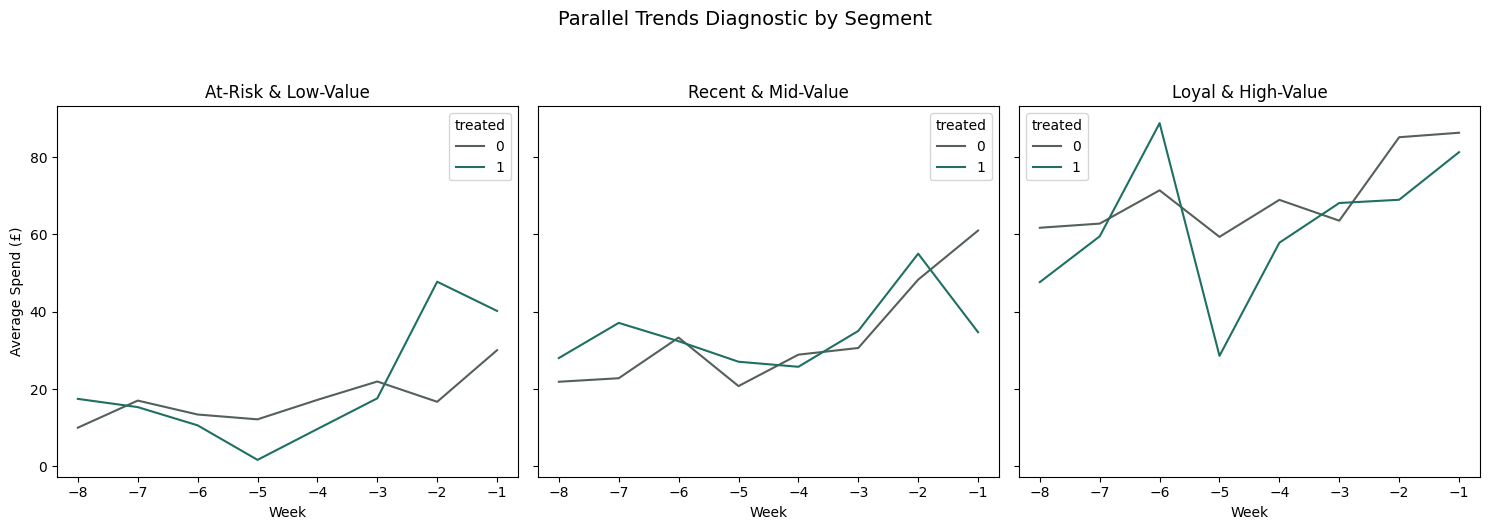

In [ ]:
segments = pre_panel['Segment'].unique()
num_segments = len(segments)

fig, axes = plt.subplots(nrows=1, ncols=num_segments, figsize=(15, 5), sharey=True)

for i, segment in enumerate(segments):
    ax = axes[i]

    segment_data = pre_panel[pre_panel['Segment'] == segment]

    sns.lineplot(data=segment_data,
        x='week',
        y='spend',
        hue='treated',
        errorbar=None,
        palette=['#55605A', '#1F6F62'],
        ax=ax,
    )

    ax.set_title(segment)
    ax.set_xlabel("Week")
    ax.set_ylabel("Average Spend (£)")

plt.suptitle('Parallel Trends Diagnostic by Segment', y=1.05, fontsize=14)
plt.tight_layout()
plt.show()

* Loyal and High-Value Volatility: At week -5, the treated group experiences a severe, isolated crash (dropping from roughly £90 down to £30), while the control group remains completely stable around £60 to £70.   

* Recent and Mid-Value: It follows the general trend till week -2, where they experience a sharp opposite trends following till week -1.

* At-Risk and Low-Value Spikes: Between weeks -3 and -2, the treated group suddenly surges to nearly £50, whereas the control group stays essentially flat under £20.

* Overall Impact: These segment-level swings cascade into the overall chart, creating a visible dip at week -5 and a spike at week -2 for the treated group that the control group does not experience to the same degree.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import NearestNeighbors

In [ ]:
covariates = pre_panel.groupby('Customer ID').agg(pre_spend_total=('spend', 'sum'),
                                                  pre_active_weeks=('spend', lambda x: (x > 0).sum())).reset_index()

covariates

,Customer ID,pre_spend_total,pre_active_weeks
0,12348,222.16,1
1,12353,0.00,0
2,12356,0.00,0
3,12359,0.00,0
4,12361,114.00,1
...,...,...,...
2228,18277,0.00,0
2229,18283,92.00,1
2230,18284,0.00,0
2231,18286,833.48,1


In [ ]:
covariates['log_pre_spend'] = np.log1p(covariates['pre_spend_total'])
treatment_map = panel[['Customer ID', 'treated', 'Segment']]
psm_data = covariates.merge(treatment_map, on='Customer ID')

In [ ]:
X = psm_data[['log_pre_spend', 'pre_active_weeks']]
y = psm_data['treated']
log_reg = LogisticRegression(random_state=42)
log_reg.fit(X, y)
psm_data['propensity_score'] = log_reg.predict_proba(X)[:, 1]

In [ ]:
treated_df = psm_data[psm_data['treated'] == 1].reset_index(drop=True)
control_df = psm_data[psm_data['treated'] == 0].reset_index(drop=True)

knn = NearestNeighbors(n_neighbors=1, algorithm='ball_tree')
knn.fit(control_df[['propensity_score']])

distances, indices = knn.kneighbors(treated_df[['propensity_score']])

matched_control_df = control_df.iloc[indices.flatten()].reset_index(drop=True)
matched_sample = pd.concat([treated_df, matched_control_df])

balance_check = matched_sample.groupby('treated')[['pre_spend_total', 'pre_active_weeks', 'propensity_score']].mean().T
balance_check.columns = ['Matched Control (0)', 'Treated (1)']
balance_check['Difference'] = balance_check['Treated (1)'] - balance_check['Matched Control (0)']

print("Covariate Balance Check:")
display(balance_check.round(3))

Covariate Balance Check:


,Matched Control (0),Treated (1),Difference
pre_spend_total,321.786,309.342,-12.444
pre_active_weeks,0.842,0.866,0.024
propensity_score,0.284,0.284,0.000


In [ ]:
post_panel = panel[panel['week'] > 0]
post_spend = post_panel.groupby('Customer ID').agg(post_spend_avg=('spend', 'mean')).reset_index()

matched_outcomes = matched_sample.merge(post_spend, on='Customer ID', how='left').fillna(0)

treated_outcome = matched_outcomes[matched_outcomes['treated'] == 1]['post_spend_avg'].mean()
control_outcome = matched_outcomes[matched_outcomes['treated'] == 0]['post_spend_avg'].mean()
psm_effect = treated_outcome - control_outcome

comparison_df = pd.DataFrame({
    'Method': ['Difference-in-Differences (Overall)', 'Propensity Score Matching (1-NN)'],
    'Estimated Effect (£/week)': [round(effect_size_overall, 2), round(psm_effect, 2)]
})

print("\nMethod Comparison:")
display(comparison_df)


Method Comparison:


,Method,Estimated Effect (£/week)
0,Difference-in-Differences (Overall),-2.86
1,Propensity Score Matching (1-NN),-3.84
